In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

sales = pd.read_csv("../m5-forecasting-accuracy/sales_train_evaluation.csv")
calendar = pd.read_csv("../m5-forecasting-accuracy/calendar.csv")
prices = pd.read_csv("../m5-forecasting-accuracy/sell_prices.csv")

print(sales.shape)
sales.iloc[:3, :10]

(30490, 1947)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


In [3]:
subset = sales[(sales["store_id"] == "CA_1") & (sales["cat_id"] == "FOODS")].copy()
print(subset.shape)

(1437, 1947)


In [4]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
long = subset.melt(id_vars=id_cols, var_name="d", value_name="sales")
print(long.shape)
long.head()

(2789217, 8)


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1,3
1,FOODS_1_002_CA_1_evaluation,FOODS_1_002,FOODS_1,FOODS,CA_1,CA,d_1,0
2,FOODS_1_003_CA_1_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_1,CA,d_1,0
3,FOODS_1_004_CA_1_evaluation,FOODS_1_004,FOODS_1,FOODS,CA_1,CA,d_1,0
4,FOODS_1_005_CA_1_evaluation,FOODS_1_005,FOODS_1,FOODS,CA_1,CA,d_1,3


In [5]:
cal_cols = ["d", "date", "wm_yr_wk", "weekday", "month", "year",
            "event_name_1", "event_type_1", "snap_CA"]
long = long.merge(calendar[cal_cols], on="d", how="left")
long["date"] = pd.to_datetime(long["date"])

In [6]:
long = long.merge(prices, on=["store_id", "item_id", "wm_yr_wk"], how="left")


In [7]:
print(long.shape)
print(long["date"].min(), long["date"].max())
print(long["sales"].describe())
print((long["sales"] == 0).mean())     # share of zero-sales days
print(long["sell_price"].isna().mean())  # share of missing prices

(2789217, 17)
2011-01-29 00:00:00 2016-05-22 00:00:00
count    2.789217e+06
mean     1.961719e+00
std      5.379334e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      2.000000e+00
max      6.480000e+02
Name: sales, dtype: float64
0.5691862626679818
0.18965035707153657


In [8]:
before = len(long)
long = long[long["sell_price"].notna()].copy()
print(before, "->", len(long))
print((long["sales"] == 0).mean())

2789217 -> 2260241
0.4683606748129956


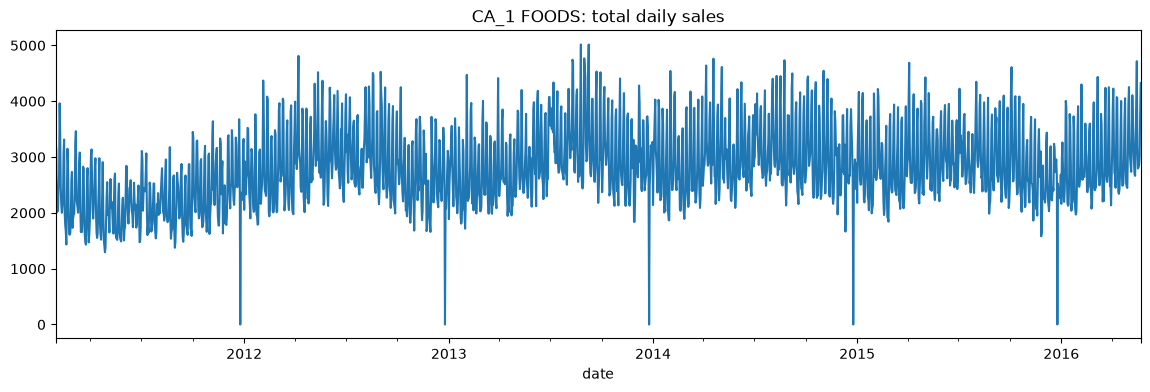

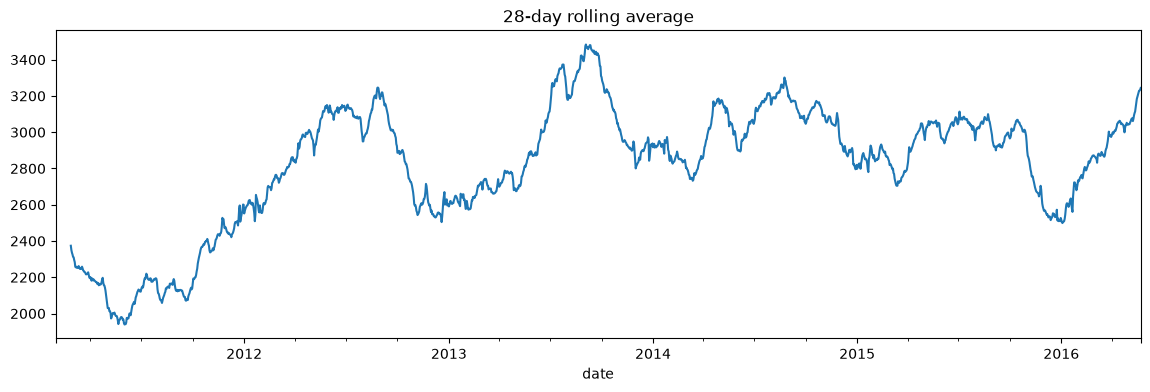

In [9]:
daily = long.groupby("date")["sales"].sum()
daily.plot(figsize=(14, 4), title="CA_1 FOODS: total daily sales")
plt.show()

daily.rolling(28).mean().plot(figsize=(14, 4), title="28-day rolling average")
plt.show()


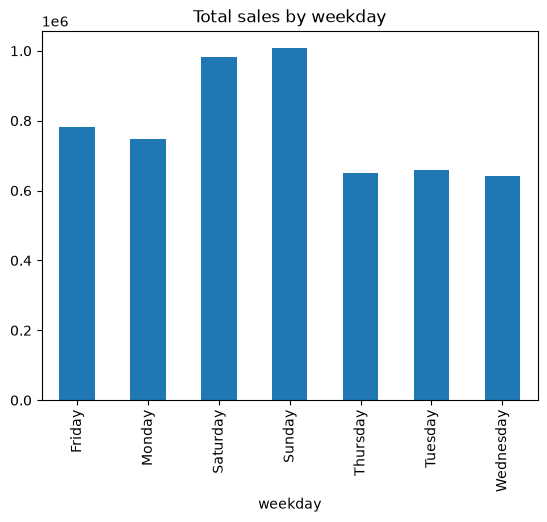

In [10]:
long.groupby("weekday")["sales"].sum().plot(kind="bar", title="Total sales by weekday")
plt.show()

In [11]:
print(long.groupby("snap_CA")["sales"].mean())
print(long.groupby(long["event_name_1"].notna())["sales"].mean())

snap_CA
0    2.326593
1    2.612983
Name: sales, dtype: float64
event_name_1
False    2.429654
True     2.321100
Name: sales, dtype: float64


In [12]:
long.nlargest(5, "sales")[["item_id", "date", "sales", "sell_price", "event_name_1"]]

,item_id,date,sales,sell_price,event_name_1
734264,FOODS_3_785,2012-06-22,648,3.34,NaN
1360104,FOODS_3_090,2013-09-01,599,1.00,NaN
1358667,FOODS_3_090,2013-08-31,432,1.00,NaN
836291,FOODS_3_785,2012-09-01,427,3.34,NaN
1390281,FOODS_3_090,2013-09-22,369,1.00,NaN


In [13]:
item_stats = long.groupby("item_id")["sales"].agg(["mean", lambda s: (s == 0).mean()])
item_stats.columns = ["avg_sales", "zero_share"]
item_stats.describe()

,avg_sales,zero_share
count,1437.000000,1437.000000
mean,2.258842,0.480113
std,3.970364,0.209355
min,0.050868,0.003091
25%,0.636364,0.326237
50%,1.120041,0.493045
75%,2.194230,0.644990
max,66.385884,0.963400


In [14]:
daily.nsmallest(5)

date
2011-12-25    0
2012-12-25    0
2013-12-25    0
2014-12-25    0
2015-12-25    0
Name: sales, dtype: int64

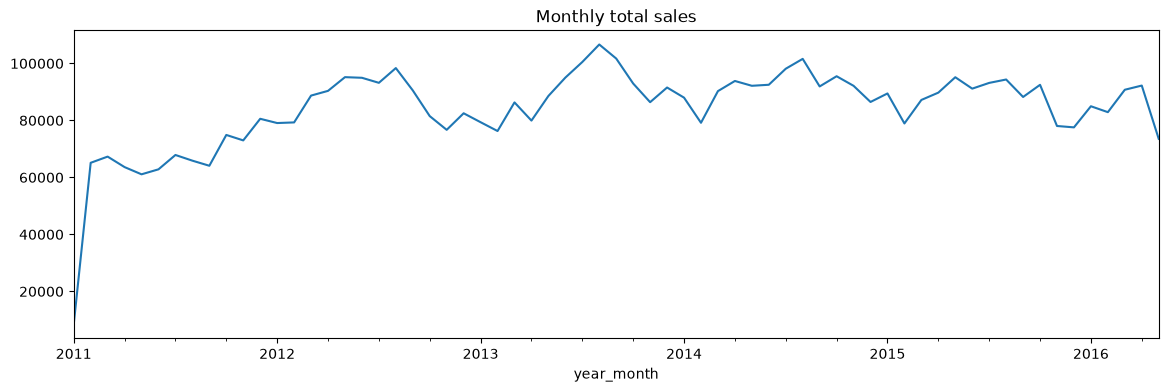

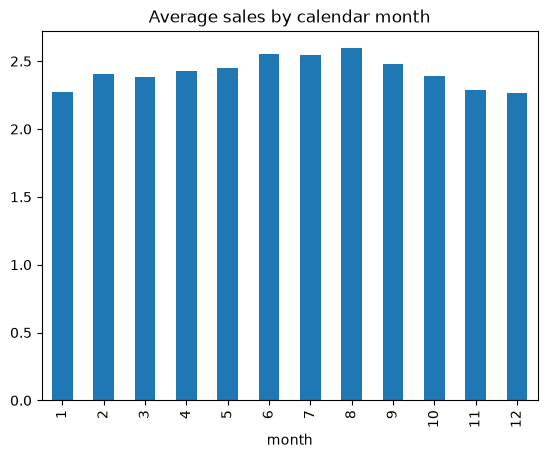

In [15]:
# Monthly totals over time
long["year_month"] = long["date"].dt.to_period("M")
monthly = long.groupby("year_month")["sales"].sum()
monthly.plot(figsize=(14, 4), title="Monthly total sales")
plt.show()

# Average sales per item-day by calendar month (averaged across all years)
long.groupby("month")["sales"].mean().plot(kind="bar", title="Average sales by calendar month")
plt.show()

In [16]:
# By event type
long.groupby("event_type_1")["sales"].mean()

# By individual event (lowest to highest)
long.groupby("event_name_1")["sales"].mean().sort_values()

event_name_1
Christmas              0.000000
Thanksgiving           1.467094
NewYear                1.742518
LentWeek2              1.870878
Halloween              1.921827
LentStart              1.960896
NBAFinalsStart         2.061135
StPatricksDay          2.208973
Chanukah End           2.218865
ValentinesDay          2.225816
MartinLutherKingDay    2.310842
Cinco De Mayo          2.329668
PresidentsDay          2.350103
EidAlAdha              2.354926
OrthodoxChristmas      2.365212
NBAFinalsEnd           2.383292
VeteransDay            2.464877
ColumbusDay            2.521828
MemorialDay            2.546354
Eid al-Fitr            2.556532
Purim End              2.560203
Ramadan starts         2.562478
Pesach End             2.566881
IndependenceDay        2.577890
Easter                 2.651234
Mother's day           2.671431
Father's day           2.854224
LaborDay               3.131746
SuperBowl              3.146186
OrthodoxEaster         3.146905
Name: sales, dtype: float64

In [17]:
last = long["date"].max()
val_start = last - pd.Timedelta(days=27)       # last 28 days = validation
train_end = val_start - pd.Timedelta(days=1)

train = long[long["date"] <= train_end]
val = long[long["date"] >= val_start]
print(train_end, val_start, last)

2016-04-24 00:00:00 2016-04-25 00:00:00 2016-05-22 00:00:00


In [18]:
#split the data into train and validation sets

last = long["date"].max()
val_start = last - pd.Timedelta(days=27)
train_end = val_start - pd.Timedelta(days=1)

train = long[long["date"] <= train_end]
val = long[long["date"] >= val_start]

print(train_end, val_start, last)

2016-04-24 00:00:00 2016-04-25 00:00:00 2016-05-22 00:00:00


In [19]:
item = "FOODS_3_090"

item_train = train[train["item_id"] == item]
item_val = val[val["item_id"] == item]

In [20]:
recent = item_train[item_train["date"] > train_end - pd.Timedelta(days=28)]
avg = recent["sales"].mean()
print("28-day average:", avg)

28-day average: 50.82142857142857


In [21]:
print(item_val[["date", "sales"]].head(7))

              date  sales
2749683 2016-04-25     48
2751120 2016-04-26     35
2752557 2016-04-27     34
2753994 2016-04-28     67
2755431 2016-04-29     63
2756868 2016-04-30     99
2758305 2016-05-01     71


In [22]:
total_error = (item_val["sales"] - avg).abs().sum()
total_actual = item_val["sales"].sum()
print("WAPE:", total_error / total_actual)

WAPE: 0.30067450709097204


In [23]:
weekday_avg = recent.groupby("weekday")["sales"].mean()
print(weekday_avg)

weekday
Friday       62.00
Monday       36.25
Saturday     79.50
Sunday       65.50
Thursday     39.25
Tuesday      36.75
Wednesday    36.50
Name: sales, dtype: float64


In [24]:
item_val = item_val.copy()
item_val["pred"] = item_val["weekday"].map(weekday_avg)

In [25]:
total_error = (item_val["sales"] - item_val["pred"]).abs().sum()
total_actual = item_val["sales"].sum()
print("Weekday WAPE:", total_error / total_actual)

Weekday WAPE: 0.21519370460048426


In [26]:
recent_all = train[train["date"] > train_end - pd.Timedelta(days=28)]

In [27]:
flat = recent_all.groupby("item_id")["sales"].mean().rename("pred_flat").reset_index()

wk = (recent_all.groupby(["item_id", "weekday"])["sales"].mean()
      .rename("pred_weekday").reset_index())

In [28]:
v = val.merge(flat, on="item_id", how="left")
v = v.merge(wk, on=["item_id", "weekday"], how="left")
v[["pred_flat", "pred_weekday"]] = v[["pred_flat", "pred_weekday"]].fillna(0)

In [29]:
def wape(actual, pred):
    return (actual - pred).abs().sum() / actual.sum()

print("Flat WAPE:   ", wape(v["sales"], v["pred_flat"]))
print("Weekday WAPE:", wape(v["sales"], v["pred_weekday"]))

Flat WAPE:    0.6739927748096586
Weekday WAPE: 0.6852410467561348


In [30]:
v["segment"] = pd.cut(
    v["pred_flat"],
    bins=[-0.01, 0.5, 2, 10, 1000],
    labels=["very slow (<0.5/day)", "slow (0.5-2)", "medium (2-10)", "fast (>10)"]
)

In [31]:
rows = []
for name, g in v.groupby("segment", observed=True):
    rows.append({
        "segment": name,
        "items": g["item_id"].nunique(),
        "sales_share": g["sales"].sum() / v["sales"].sum(),
        "WAPE_flat": wape(g["sales"], g["pred_flat"]),
        "WAPE_weekday": wape(g["sales"], g["pred_weekday"]),
    })

pd.DataFrame(rows)

,segment,items,sales_share,WAPE_flat,WAPE_weekday
0,very slow (<0.5/day),318,0.068720,1.109340,1.103092
1,slow (0.5-2),723,0.255293,0.941385,0.984001
2,medium (2-10),360,0.461958,0.609985,0.628893
3,fast (>10),36,0.214030,0.353425,0.316342


In [32]:
vs = v[v["segment"] == "very slow (<0.5/day)"]
print(wape(vs["sales"], 0 * vs["sales"]))

1.0


In [33]:
v["pred_hybrid"] = np.where(v["pred_flat"] > 10, v["pred_weekday"], v["pred_flat"])
print("Hybrid WAPE:", wape(v["sales"], v["pred_hybrid"]))

Hybrid WAPE: 0.6660559173742708


In [34]:
lag = long[["item_id", "date", "sales"]].copy()
lag["date"] = lag["date"] + pd.Timedelta(days=28)
lag = lag.rename(columns={"sales": "lag_28"})

long = long.merge(lag, on=["item_id", "date"], how="left")

In [35]:
chk = long[long["item_id"] == "FOODS_3_090"].sort_values("date")
chk[["date", "sales", "lag_28"]].iloc[28:40]

,date,sales,lag_28
18903,2011-02-26,0,107.0
19600,2011-02-27,0,182.0
20297,2011-02-28,0,47.0
20994,2011-03-01,0,47.0
21691,2011-03-02,0,62.0
22388,2011-03-03,0,90.0
23085,2011-03-04,0,81.0
23787,2011-03-05,0,124.0
24501,2011-03-06,0,134.0
25215,2011-03-07,0,65.0


In [36]:
long[(long["item_id"] == "FOODS_3_090") & (long["date"] == "2011-01-29")]["sales"]

320    107
Name: sales, dtype: int64

In [37]:
long["dow"] = long["date"].dt.dayofweek
long["is_christmas"] = ((long["date"].dt.month == 12) & (long["date"].dt.day == 25)).astype(int)
long["has_event"] = long["event_name_1"].notna().astype(int)

/var/folders/d7/pfkcn93111vgn3sjyz41n6yw0000gn/T/ipykernel_68368/2225191626.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  long["dow"] = long["date"].dt.dayofweek


In [38]:
features = ["lag_28", "dow", "month", "snap_CA", "sell_price", "is_christmas", "has_event"]
print(long[features].dtypes)
long[features].isna().mean()

lag_28          float64
dow               int32
month             int64
snap_CA           int64
sell_price      float64
is_christmas      int64
has_event         int64
dtype: object


lag_28          0.017802
dow             0.000000
month           0.000000
snap_CA         0.000000
sell_price      0.000000
is_christmas    0.000000
has_event       0.000000
dtype: float64

In [39]:
gaps = long.groupby("item_id")["date"].agg(lambda s: (s.max() - s.min()).days + 1 - len(s))
print(gaps.sum(), (gaps > 0).sum())

0 0


In [40]:
long = long.sort_values(["item_id", "date"]).reset_index(drop=True)

g = long.groupby("item_id")["sales"]
long["roll7_l28"] = g.transform(lambda s: s.shift(28).rolling(7).mean())
long["roll28_l28"] = g.transform(lambda s: s.shift(28).rolling(28).mean())

In [41]:
chk = long[long["item_id"] == "FOODS_3_090"].reset_index(drop=True)
i = 100
print(chk.loc[i, "roll7_l28"], chk.loc[i - 34 : i - 28, "sales"].mean())

0.0 0.0


In [42]:
i = (chk["roll7_l28"] > 5).idxmax()
print(i, chk.loc[i, "roll7_l28"], chk.loc[i - 34 : i - 28, "sales"].mean())

34 88.0 88.0


In [43]:
features = ["lag_28", "roll7_l28", "roll28_l28", "dow", "month",
            "snap_CA", "sell_price", "is_christmas", "has_event"]

train = long[long["date"] <= train_end]
val = long[long["date"] >= val_start].copy()
print(len(train), len(val))

2220005 40236


In [44]:
import lightgbm as lgb

model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05,
                          num_leaves=63, random_state=42, verbose=-1)
model.fit(train[features], train["sales"])

,num_leaves,63
,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [45]:
val = long[long["date"] >= val_start].copy()
val["pred_lgb"] = model.predict(val[features]).clip(min=0)

In [46]:
print("LightGBM WAPE:", wape(val["sales"], val["pred_lgb"]))

LightGBM WAPE: 0.6762467022609661


In [47]:
recent_all = train[train["date"] > train_end - pd.Timedelta(days=28)]
flat = recent_all.groupby("item_id")["sales"].mean().rename("pred_flat").reset_index()

val = val.merge(flat, on="item_id", how="left")
val["pred_flat"] = val["pred_flat"].fillna(0)

val["segment"] = pd.cut(
    val["pred_flat"],
    bins=[-0.01, 0.5, 2, 10, 1000],
    labels=["very slow (<0.5/day)", "slow (0.5-2)", "medium (2-10)", "fast (>10)"]
)

In [48]:
rows = []
for name, g in val.groupby("segment", observed=True):
    rows.append({
        "segment": name,
        "items": g["item_id"].nunique(),
        "sales_share": g["sales"].sum() / val["sales"].sum(),
        "WAPE_flat": wape(g["sales"], g["pred_flat"]),
        "WAPE_lgb": wape(g["sales"], g["pred_lgb"]),
    })
pd.DataFrame(rows)

,segment,items,sales_share,WAPE_flat,WAPE_lgb
0,very slow (<0.5/day),318,0.068720,1.109340,1.261723
1,slow (0.5-2),723,0.255293,0.941385,0.962838
2,medium (2-10),360,0.461958,0.609985,0.601900
3,fast (>10),36,0.214030,0.353425,0.306892


In [49]:
model_l1 = lgb.LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                             num_leaves=63, random_state=42, verbose=-1)
model_l1.fit(train[features], train["sales"])

val["pred_l1"] = model_l1.predict(val[features]).clip(min=0)
print("LightGBM L1 WAPE:", wape(val["sales"], val["pred_l1"]))

LightGBM L1 WAPE: 0.6473391679062399


In [50]:
rows = []
for name, g in val.groupby("segment", observed=True):
    rows.append({
        "segment": name,
        "WAPE_flat": wape(g["sales"], g["pred_flat"]),
        "WAPE_lgb": wape(g["sales"], g["pred_lgb"]),
        "WAPE_l1": wape(g["sales"], g["pred_l1"]),
        "actual_total": g["sales"].sum(),
        "l1_pred_total": g["pred_l1"].sum(),
    })
pd.DataFrame(rows)

,segment,WAPE_flat,WAPE_lgb,WAPE_l1,actual_total,l1_pred_total
0,very slow (<0.5/day),1.109340,1.261723,1.006325,6242,251.569993
1,slow (0.5-2),0.941385,0.962838,0.900907,23189,12950.602239
2,medium (2-10),0.609985,0.601900,0.598547,41961,32581.726614
3,fast (>10),0.353425,0.306892,0.334938,19441,16808.526952


In [51]:
def run_window(vs):
    tr_end = vs - pd.Timedelta(days=1)
    tr = long[long["date"] <= tr_end]
    va = long[(long["date"] >= vs) & (long["date"] <= vs + pd.Timedelta(days=27))].copy()

    flat = (tr[tr["date"] > tr_end - pd.Timedelta(days=28)]
            .groupby("item_id")["sales"].mean().rename("pred_flat").reset_index())
    va = va.merge(flat, on="item_id", how="left")
    va["pred_flat"] = va["pred_flat"].fillna(0)

    m_def = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=63,
                              random_state=42, verbose=-1).fit(tr[features], tr["sales"])
    m_l1 = lgb.LGBMRegressor(objective="l1", n_estimators=300, learning_rate=0.05,
                             num_leaves=63, random_state=42, verbose=-1).fit(tr[features], tr["sales"])

    va["pred_lgb"] = m_def.predict(va[features]).clip(min=0)
    va["pred_l1"] = m_l1.predict(va[features]).clip(min=0)

    return {"window_start": vs.date(),
            "WAPE_flat": wape(va["sales"], va["pred_flat"]),
            "WAPE_lgb": wape(va["sales"], va["pred_lgb"]),
            "WAPE_l1": wape(va["sales"], va["pred_l1"])}

results = [run_window(val_start - pd.Timedelta(days=28 * k)) for k in [1, 2, 3]]
pd.DataFrame(results)

,window_start,WAPE_flat,WAPE_lgb,WAPE_l1
0,2016-03-28,0.683664,0.696976,0.646485
1,2016-02-29,0.695514,0.712259,0.664624
2,2016-02-01,0.688977,0.724295,0.670049


In [52]:
model_q90 = lgb.LGBMRegressor(objective="quantile", alpha=0.9, n_estimators=300,
                              learning_rate=0.05, num_leaves=63, random_state=42, verbose=-1)
model_q90.fit(train[features], train["sales"])
val["pred_q90"] = model_q90.predict(val[features]).clip(min=0)

def service(actual, stock):
    short = (actual - stock).clip(lower=0).sum()
    over = (stock - actual).clip(lower=0).sum()
    return {"fill_rate": 1 - short / actual.sum(),
            "leftover_units": over,
            "total_stock": stock.sum()}

pd.DataFrame({name: service(val["sales"], val[col])
              for name, col in [("flat", "pred_flat"), ("L1", "pred_l1"), ("q90", "pred_q90")]}).T

,fill_rate,leftover_units,total_stock
flat,0.629068,27527.892857,84668.000000
L1,0.520877,15279.592218,62592.425798
q90,0.892281,106572.832130,187621.407745


   quantile  fill_rate  stock_vs_demand  leftover_units
0       0.5   0.520814         0.689046    15281.055676
1       0.6   0.613933         0.888482    24938.119514
2       0.7   0.713729         1.163028    40811.178739
3       0.8   0.803917         1.504288    63616.837083
4       0.9   0.892281         2.065564   106572.832130


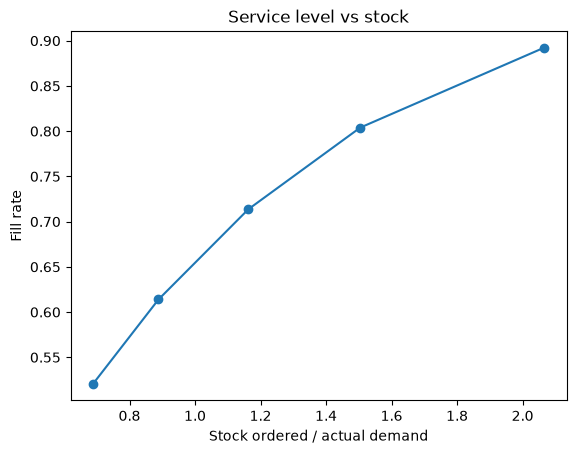

In [53]:
actual_total = val["sales"].sum()
rows = []
for a in [0.5, 0.6, 0.7, 0.8, 0.9]:
    m = lgb.LGBMRegressor(objective="quantile", alpha=a, n_estimators=300,
                          learning_rate=0.05, num_leaves=63,
                          random_state=42, verbose=-1).fit(train[features], train["sales"])
    stock = pd.Series(m.predict(val[features]).clip(min=0), index=val.index)
    s = service(val["sales"], stock)
    rows.append({"quantile": a,
                 "fill_rate": s["fill_rate"],
                 "stock_vs_demand": s["total_stock"] / actual_total,
                 "leftover_units": s["leftover_units"]})

curve = pd.DataFrame(rows)
print(curve)

plt.plot(curve["stock_vs_demand"], curve["fill_rate"], marker="o")
plt.xlabel("Stock ordered / actual demand")
plt.ylabel("Fill rate")
plt.title("Service level vs stock")
plt.show()

In [54]:
curve["extra_stock_per_extra_unit_served"] = curve["stock_vs_demand"].diff() / curve["fill_rate"].diff()
curve

,quantile,fill_rate,stock_vs_demand,leftover_units,extra_stock_per_extra_unit_served
0,0.5,0.520814,0.689046,15281.055676,NaN
1,0.6,0.613933,0.888482,24938.119514,2.141733
2,0.7,0.713729,1.163028,40811.178739,2.751058
3,0.8,0.803917,1.504288,63616.837083,3.783904
4,0.9,0.892281,2.065564,106572.832130,6.351821


In [58]:
val[["item_id", "dept_id", "date", "sales", "pred_flat", "pred_lgb", "pred_l1", "pred_q90"]] \
    .to_csv("../results/val_predictions.csv", index=False)

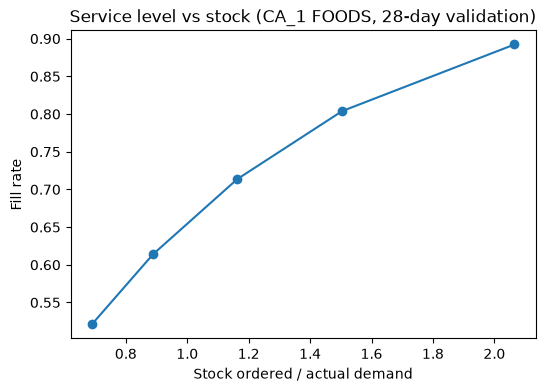

In [61]:
import os
os.makedirs("../results", exist_ok=True)

curve.to_csv("../results/service_curve.csv", index=False)

plt.figure(figsize=(6, 4))
plt.plot(curve["stock_vs_demand"], curve["fill_rate"], marker="o")
plt.xlabel("Stock ordered / actual demand")
plt.ylabel("Fill rate")
plt.title("Service level vs stock (CA_1 FOODS, 28-day validation)")
plt.savefig("../results/service_curve.png", dpi=150, bbox_inches="tight")
plt.show()

val[["item_id", "dept_id", "date", "sales", "pred_flat", "pred_lgb", "pred_l1", "pred_q90"]] \
    .to_parquet("../results/val_predictions.parquet")

In [60]:
long.to_parquet("../long_features.parquet")